# Physical AI 基础篇 智能机器人课程 2026 Spring 第4讲练习资料


## Colab 执行步骤

**预计耗时**：T4 GPU 约 30 分钟

### 步骤

1. 从上到下执行到“5. 让它走起来 — 从 checkpoint 到视频”。
2. 执行途中可能出现“session 崩溃”。（**这是预期行为，请直接继续步骤 3。**）
3. 把 log 文件保存到 Google Drive：

```python
   from google.colab import drive
   drive.mount('/content/drive')
   !cp -r logs /content/drive/MyDrive/
```

4. 断开并重启运行时（菜单：运行时 → 断开运行时并删除）。
5. 把 log 文件从 Google Drive 放回 `/content` 根目录：

```python
   from google.colab import drive
   drive.mount('/content/drive')
   !cp -r /content/drive/MyDrive/logs/ /content/logs/
```

6. 再次按“0. 环境准备”→“5. 让它走起来 — 从 checkpoint 到视频”的顺序执行。
   → 程序会利用步骤 5 恢复的日志生成后续视频。


# 使用 RSL-RL 的 PPO 让 Unitree G1 走起来

本 notebook 只有一个目标：**用强化学习（PPO）让人形机器人 Unitree G1 学会“走路”**。过程中会用真实代码观察两件事：

1. **如何定义 MDP**：观测、动作、奖励、终止条件和指令分别写在哪些文件中（§1–2）；
2. **如何训练**：RSL-RL 的 PPO 如何学习这个 MDP（§3–5）。

唯一需要安装的是可通过 `pip install` 获取的 [mjlab](https://github.com/mujocolab/mjlab)。mjlab 是“Isaac Lab API × MuJoCo Warp 物理”的 GPU 并行 RL 库，内置 G1 机器人模型、速度跟踪任务以及训练/回放 CLI。流程与真实开发一致：

| 小节 | 实务步骤 | 使用内容 |
| --- | --- | --- |
| §1 | 阅读任务定义（= MDP） | `mjlab/tasks/velocity/` |
| §2 | 缩小环境并运行确认 | `ManagerBasedRlEnv` |
| §3 | 启动训练 | `mjlab.scripts.train`（RSL-RL 的 PPO） |
| §4 | 用训练曲线诊断 | TensorBoard 日志 |
| §5 | 让机器人走并用视频确认 | 回放环境 + checkpoint |

技术栈分三层：**MuJoCo Warp**（在 GPU 上并行仿真数千个实例）/ **mjlab**（以 manager 方式描述任务的环境库及内置任务）/ **RSL-RL**（腿式机器人 RL 中常用的 PPO 实现）。


<div style="border:2px solid #5cb85c; padding:12px; border-radius:6px;">

✅ **本 notebook 已在 GPU 服务器上完成全 cell 执行与验证（RTX 3090 / CUDA 12.4，2026-07-04）**

- 物理引擎是 MuJoCo Warp = CUDA。**必须使用 NVIDIA GPU**（Colab：运行时 → 更改运行时类型 → GPU）。
- §0 的安装 cell 固定为已验证的版本组合（直接使用最新版本可能因为不兼容而失败，原因见 cell 内注释）。
- 训练结果（`logs/`）和视频（`videos/`）会作为文件保留；即使 session 断开，重新执行 §0 后也能从 §4–5 恢复。

</div>


## 0. 环境准备

只需安装 `mjlab`（依赖的 mujoco-warp / rsl_rl / mediapy / tensorboard 等会一并安装）。numpy 使用 Colab 已有版本的兼容范围，**通常无需重启运行时**。

> ⚠️ 如果安装 cell 末尾出现“需要重启运行时以完成 numpy 替换”的 RuntimeError（仅在 pip 替换了 numpy 时发生），请菜单选择**运行时 → 重启 session**（不是“断开并删除”——删除会换一台新机器，需要从头开始），然后再次从上到下执行。第二次安装只需几秒。
>
> ℹ️ pip 显示的依赖警告（如 moviepy / numba）来自本 notebook 不使用的 Colab 内置包之间的冲突，可以忽略。


In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks":   # 仓库内，開場合是仓库直下，作業
    os.chdir("..")
os.environ["MUJOCO_GL"] = "egl"        # GPU描画后端(训练・视频的両方到使用)
os.environ["WANDB_MODE"] = "offline"   # 跳过实验管理服务 (wandb) 的登录
!nvidia-smi -L || echo '⚠️ GPU 需要，(Colab: runtime → 更改 runtime 类型 → GPU)'

# ★ -整合(重要)。最新版个个同士是相互到非互換因此、検証済的組合到固定执行:
#   - mjlab 1.2.0      … 的-的検証-(G1 模型・velocity 任务・train/play CLI 同梱)
#   - mujoco 3.5.0     … 与 mujoco-warp 3.5.0 配套；版个个个过新且缺少 mjENBL_MULTICCD 时 import 会失败
#   - warp-lang 1.12.1 … mjlab 使 warp.context API 残系列列列(1.13+ ，廃止)
#   - numpy >=2.0,<2.3 … mediapy 与互換範囲(2.5 系列列会导致 mediapy 的 import ，落)。哪个版个个
#     指定範囲的是、Colab 到元从入 numpy 该使、入替(→要重新起動)避为了
#   - scipy            … mjlab.terrains 使依赖宣言到没有的，明示的到入
%pip install -q "mjlab==1.2.0" "mujoco==3.5.0" "warp-lang==1.12.1" "numpy>=2.0,<2.3" scipy

# pip  numpy 入替場合、kernel中只有旧的的 numpy 読込残(Colab 是起動时読包含済)。
# 内存与磁盘，版个个偏移進与后段的 import 新旧的的混在，壊的，、这里，検知并分还是和止
import importlib.metadata, numpy
_numpy_on_disk = importlib.metadata.version("numpy")
if numpy.__version__ != _numpy_on_disk:
    raise RuntimeError(
        f"numpy 的入替完成执行为了、runtime的重新起動需要，(内存: {numpy.__version__} / 磁盘: {_numpy_on_disk})。"
        "菜单的「runtime → session重新起動」的后、也一度上从执行并请(2次目的 install 是几秒，終)"
    )

# GPU 的没有runtime若这里，止(的先是 GPU 必須。CPU 的進与巨大 torch 的
# 避免下载和几分钟 JIT 后才遇到难以解释的错误，因此尽早停止更友好)
import shutil, subprocess, sys
if shutil.which("nvidia-smi") is None or subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode != 0:
    raise RuntimeError("GPU runtime到请切换(runtime → 更改 runtime 类型 → GPU)")

# torch  GPU 認識、驱动(CUDA 12.4)到合构建方向入替(旧的的驱动的-向。
# Colab 等新的驱动的环境，是既定的 torch ，运动的，、的分岐是执行被不。
# mjlab 是 torch>=2.7 宣言并为了依赖警告出、2.6.0+cu124 ，的動作是検証済，)
import torch
if not torch.cuda.is_available():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch==2.6.0",
                    "--index-url", "https://download.pytorch.org/whl/cu124"], check=True)
    print("↺ torch  cu124 到入替完成。runtime重新起動→上从重新执行并请。")
print("✅ install done")

GPU 0: Tesla T4 (UUID: GPU-d8b83392-df3b-7841-8640-428421e1745e)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 105.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.4/136.4 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.2/84.2 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 722.0/722.0 kB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.5/559.5 kB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 741.0/741.0 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.0/215.0 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 96.1

In [ ]:
import os, sys, torch
assert torch.cuda.is_available(), "CUDA GPU 未找到(GPUruntime选择。torch 入替直后若runtime重新起動→上从重新执行)"

TASK   = "Mjlab-Velocity-Flat-Unitree-G1"   # mjlab 同梱: 平地，速度命令到追従并歩 G1 任务
DEVICE = "cuda:0"
_vram_gb       = torch.cuda.get_device_properties(0).total_memory / 1e9
NUM_ENVS       = 4096 if _vram_gb >= 20 else 2048   # 並列体几。24GB級(3090/A100)是4096、T4/L4(16GB)是2048
MAX_ITERATIONS = 500   # 较短示范用。滑还是到歩中只有个来 几千〜几万 iter 需要
print(f"GPU: {torch.cuda.get_device_name(0)} ({_vram_gb:.0f} GB) → num_envs={NUM_ENVS}, iterations={MAX_ITERATIONS}")

GPU: Tesla T4 (16 GB) → num_envs=2048, iterations=500


## 1. 阅读任务定义（=MDP）

机器人 RL 的实务中，花在**设计 MDP** 上的时间往往多于编写学习算法。mjlab 采用声明式写法：把小的 term 函数（计算一个观测项、奖励项等的函数）通过 Cfg（配置对象）组合起来，这与 Isaac Lab 的 manager 方式相同。

“让 G1 走路”的任务以 **velocity（速度跟踪）任务**的形式内置于 mjlab。定义位于 pip 包中，全部是普通 Python 文件：

- MDP 主体：`mjlab/tasks/velocity/velocity_env_cfg.py`
- G1 专属调整：`mjlab/tasks/velocity/config/g1/env_cfgs.py`（机器人模型、各关节系数等）
- term 函数实现：`mjlab/tasks/velocity/mdp/*.py`
- 机器人模型：`mjlab/asset_zoo/robots/unitree_g1/`（MJCF + 执行器定义）

重点是“走路”的定义方式：不是直接把走路动作写进奖励，而是构造这样的 MDP：**在不摔倒的情况下持续跟踪随机给出的目标速度（前后、左右、旋转）**。于是 PPO 会在整形奖励的引导下把走路找到作为解决方案。

任务通过 `register_mjlab_task(task_id="Mjlab-Velocity-Flat-Unitree-G1", ...)` 注册，并用 `load_env_cfg()` 取出。§3 的训练脚本也使用完全相同的入口。


In [ ]:
import inspect
import mjlab.tasks   # noqa: F401  ← 的 import 的瞬間到同梱任务的 register_mjlab_task() 走、登録被
from mjlab.tasks.registry import load_env_cfg
from mjlab.tasks.velocity.velocity_env_cfg import make_velocity_env_cfg

print("定義文条的实体:", inspect.getfile(make_velocity_env_cfg))

cfg = load_env_cfg(TASK)   # deepcopy 已注意意册的 Cfg，修改它不会污染注意意册表

print(f"\nMDP 的構成要素({type(cfg).__name__}):")
print(f"  观测         : actor {len(cfg.observations['actor'].terms)} 項 / critic {len(cfg.observations['critic'].terms)} 項")
print(f"  动作         : {list(cfg.actions.keys())}")
print(f"  命令     : {list(cfg.commands.keys())}")
print(f"  報酬         : {len(cfg.rewards)} 項")
print(f"  終了条条     : {list(cfg.terminations.keys())}")
print(f"  事条(DR) : {list(cfg.events.keys())}")
print(f"  课程学习 : {list(cfg.curriculum.keys())}")
print(f"  制御周期     : 物理 {cfg.sim.mujoco.timestep*1e3:.0f} ms × decimation {cfg.decimation} = 制御 {cfg.sim.mujoco.timestep*cfg.decimation*1e3:.0f} ms(50 Hz)")
print(f"  episode長 : {cfg.episode_length_s:.0f} s")

定義ファイルの実体: /usr/local/lib/python3.12/dist-packages/mjlab/tasks/velocity/velocity_env_cfg.py

MDP の構成要素(ManagerBasedRlEnvCfg):
  観測         : actor 7 項 / critic 11 項
  行動         : ['joint_pos']
  コマンド     : ['twist']
  報酬         : 14 項
  終了条件     : ['time_out', 'fell_over']
  イベント(DR) : ['reset_base', 'reset_robot_joints', 'push_robot', 'foot_friction', 'encoder_bias', 'base_com']
  カリキュラム : ['command_vel']
  制御周期     : 物理 5 ms × decimation 4 = 制御 20 ms(50 Hz)
  エピソード長 : 20 s


### 1.1 动作——让策略输出什么

策略输出的是 **29 个关节的目标角度偏移量**。它不直接输出 torque，而是把 `目标角 = 默认姿态 + scale × 动作` 交给各关节的 PD 控制器（执行器）。这种“用 RL 调节 PD 目标角”的方式是实体人形/四足机器人 RL 的事实标准，比直接输出 torque 更稳定，也能直接部署到真实机器人。`scale` 会按关节调整，以匹配活动范围与 torque 灵敏度。


In [ ]:
act = cfg.actions["joint_pos"]
print(type(act).__name__)
print("对象执行器:", act.actuator_names, " use_default_offset:", act.use_default_offset)
print("scale(关节名称称的正規表現 → 动作 1.0 的角度 [rad]):")
for i, (pat, s) in enumerate(act.scale.items()):
    if i >= 6:
        print(f"  ... 全部 {len(act.scale)} 系列統")
        break
    print(f"  {pat}: {s}")

JointPositionActionCfg
対象アクチュエータ: ('.*',)  use_default_offset: True
scale(関節名の正規表現 → 行動 1.0 あたりの角度 [rad]):
  .*_elbow_joint: 0.43857731392336724
  .*_shoulder_pitch_joint: 0.43857731392336724
  .*_shoulder_roll_joint: 0.43857731392336724
  .*_shoulder_yaw_joint: 0.43857731392336724
  .*_wrist_roll_joint: 0.43857731392336724
  .*_hip_pitch_joint: 0.5475464629911068
  ... 全 16 系統


### 1.2 观测——让策略看到什么

观测分为两组。**actor**（策略看到的观测）只包含真实机器人也能从 IMU、编码器获得的量，并且会加入噪声：机身平移/角速度、重力方向（姿态）、关节角/角速度、上一个动作和速度指令。**critic**（训练期间使用的价值函数）则额外看到足部高度、腾空时间、接触力等**只有仿真器才能取得的特权信息**，形成**非对称 actor-critic**。部署到真实机器人时只带 actor，因此既能让策略在真实机器人的信息条件下运行，又能用丰富信息帮助训练。


In [ ]:
for group_name, group in cfg.observations.items():
    print(f"[{group_name}] enable_corruption(观测噪声)={group.enable_corruption}")
    for name, term in group.terms.items():
        noise = f"  noise=U({term.noise.n_min:+.2f},{term.noise.n_max:+.2f})" if term.noise else ""
        print(f"  {name:<20} func={term.func.__name__}{noise}")
    print()

[actor] enable_corruption(観測ノイズ)=True
  base_lin_vel         func=builtin_sensor  noise=U(-0.50,+0.50)
  base_ang_vel         func=builtin_sensor  noise=U(-0.20,+0.20)
  projected_gravity    func=projected_gravity  noise=U(-0.05,+0.05)
  joint_pos            func=joint_pos_rel  noise=U(-0.01,+0.01)
  joint_vel            func=joint_vel_rel  noise=U(-1.50,+1.50)
  actions              func=last_action
  command              func=generated_commands

[critic] enable_corruption(観測ノイズ)=False
  base_lin_vel         func=builtin_sensor  noise=U(-0.50,+0.50)
  base_ang_vel         func=builtin_sensor  noise=U(-0.20,+0.20)
  projected_gravity    func=projected_gravity  noise=U(-0.05,+0.05)
  joint_pos            func=joint_pos_rel  noise=U(-0.01,+0.01)
  joint_vel            func=joint_vel_rel  noise=U(-1.50,+1.50)
  actions              func=last_action
  command              func=generated_commands
  foot_height          func=foot_height
  foot_air_time        func=foot_air_time
  foot_contac

### 1.3 指令——给任务什么目标

`twist` 指令每隔几秒随机重新采样目标速度 `(vx, vy, ωz)`。它会作为观测输入策略，也会作为奖励的参考。一些环境还会给出零速度（=保持站立）指令，因此策略也会学习“被要求停下时站稳”。**想改变任务分布，就修改这里**；例如不想要求倒着走，可以把 `lin_vel_x` 的下限设为 0。课程学习（`command_vel`）会让训练早期先从较窄的速度范围开始，再逐步扩大。


In [ ]:
tw = cfg.commands["twist"]
print(type(tw).__name__)
print(f"  重新样个间隔 : {tw.resampling_time_range} s")
print(f"  停止命令率 : {tw.rel_standing_envs:.0%}")
print(f"  vx : {tw.ranges.lin_vel_x} m/s")
print(f"  vy : {tw.ranges.lin_vel_y} m/s")
print(f"  ωz : {tw.ranges.ang_vel_z} rad/s")

UniformVelocityCommandCfg
  再サンプル間隔 : (3.0, 8.0) s
  停止コマンド率 : 10%
  vx : (-1.0, 1.0) m/s
  vy : (-1.0, 1.0) m/s
  ωz : (-0.5, 0.5) rad/s


### 1.4 奖励——定义“好的行走”

这是 MDP 设计的核心。奖励大致分两类：

- **主要目标（正权重）**：`track_linear_velocity` / `track_angular_velocity`。把跟踪误差送入指数核 `exp(−err²/σ²)`，让误差为 0 时得到有界的最大值 1。
- **整形（shaping）**：其余项负责在实现主要目标时引导**走法**，例如保持机身直立（`upright`）和基准姿态（`pose`）、抑制乱晃（`body_ang_vel` / `angular_momentum`）、抑制动作变化率（`action_rate_l2`，避免抖动）、关节活动范围限制（`dof_pos_limits`）、适当抬脚（`foot_clearance` / `foot_swing_height`），以及抑制打滑（`foot_slip`）、着地冲击（`soft_landing`）和自碰撞（`self_collisions`）。

注意：这里没有显式的“摔倒惩罚”项。摔倒会触发 §1.5 的终止条件，**失去之后本来可能得到的全部跟踪奖励**，这本身就构成最大惩罚。

步态由“加入哪些项、给每项多大权重”决定。根据训练结果调整这张表的循环，是腿式机器人 RL 开发中最耗时的工作之一（权重为 0 表示保留该项但暂时禁用）。


In [ ]:
print(f"{'term':<26} {'weight':>10}  func")
for name, r in sorted(cfg.rewards.items(), key=lambda kv: -abs(kv[1].weight)):
    print(f"{name:<26} {r.weight:>10}  {r.func.__name__}")

term                           weight  func
track_linear_velocity             2.0  track_linear_velocity
track_angular_velocity            2.0  track_angular_velocity
foot_clearance                   -2.0  feet_clearance
upright                           1.0  flat_orientation
pose                              1.0  variable_posture
dof_pos_limits                   -1.0  joint_pos_limits
self_collisions                  -1.0  self_collision_cost
foot_swing_height               -0.25  feet_swing_height
action_rate_l2                   -0.1  action_rate_l2
foot_slip                        -0.1  feet_slip
body_ang_vel                    -0.05  body_angular_velocity_penalty
angular_momentum                -0.02  angular_momentum_penalty
soft_landing                   -1e-05  soft_landing
air_time                          0.0  feet_air_time


term 的实体只是一个函数，契约是 `func(env, **params) -> Tensor(num_envs,)`（按 batch 返回所有并行环境的值）。查看主要奖励 `track_linear_velocity` 的实现，会发现它只是把指令速度和实际速度的平方误差送进指数核：


In [ ]:
print(inspect.getsource(cfg.rewards["track_linear_velocity"].func))

def track_linear_velocity(
  env: ManagerBasedRlEnv,
  std: float,
  command_name: str,
  asset_cfg: SceneEntityCfg = _DEFAULT_ASSET_CFG,
) -> torch.Tensor:
  """Reward for tracking the commanded base linear velocity.

  The commanded z velocity is assumed to be zero.
  """
  asset: Entity = env.scene[asset_cfg.name]
  command = env.command_manager.get_command(command_name)
  assert command is not None, f"Command '{command_name}' not found."
  actual = asset.data.root_link_lin_vel_b
  xy_error = torch.sum(torch.square(command[:, :2] - actual[:, :2]), dim=1)
  z_error = torch.square(actual[:, 2])
  lin_vel_error = xy_error + z_error
  return torch.exp(-lin_vel_error / std**2)



### 1.5 终止条件与事件（域随机化）

终止条件有两种，含义不同。`fell_over`（机身倾斜过大）表示**失败**，会立即结束 episode；正如 §1.4 所见，失去未来奖励就是惩罚。`time_out`（完成 20 秒）只是**截断**，不是失败，因此用 `time_out=True` 区分（PPO 会采用不同的价值 bootstrap 处理）。

事件用于向环境注入随机性，主要服务于 **sim2real 的域随机化**：重置时的姿态变化、每隔 5–6 秒的推搡（训练出被推后也能稳住的策略），以及摩擦、机身质心和编码器偏置的个体差异随机化。


In [ ]:
for name, t in cfg.terminations.items():
    print(f"終了     {name:<16} func={t.func.__name__:<18} time_out={t.time_out}")
print()
for name, e in cfg.events.items():
    print(f"事条 {name:<16} mode={e.mode:<8} func={e.func.__name__}")

終了     time_out         func=time_out           time_out=True
終了     fell_over        func=bad_orientation    time_out=False

イベント reset_base       mode=reset    func=reset_root_state_uniform
イベント reset_robot_joints mode=reset    func=reset_joints_by_offset
イベント push_robot       mode=interval func=push_by_setting_velocity
イベント foot_friction    mode=startup  func=geom_friction
イベント encoder_bias     mode=startup  func=encoder_bias
イベント base_com         mode=startup  func=body_com_offset


## 2. 创建环境并运行一次

前面看到的 Cfg 只是**声明**，还没有进行计算。传给 `ManagerBasedRlEnv(cfg, device)` 后，场景会在 GPU 上构建，所有 term 会针对全部并行环境向量化运行。训练前先创建一个小环境（16 个实例）并运行几步，检查观测、奖励和终止的形状——真实开发中新任务也通常从这个** smoke test** 开始。

> ⏳ 第一次运行可能需要几分钟，因为 MuJoCo Warp 会 JIT 编译 CUDA kernel；后续运行会使用缓存。


In [ ]:
from mjlab.envs import ManagerBasedRlEnv

smoke_cfg = load_env_cfg(TASK)
smoke_cfg.scene.num_envs = 16
env = ManagerBasedRlEnv(cfg=smoke_cfg, device=DEVICE)

obs, _ = env.reset()
# 动作 0 = 「默认姿态保」(§1.1 的 use_default_offset)。何也学，也立是
zero_action = torch.zeros(env.num_envs, env.action_manager.total_action_dim, device=DEVICE)
for _ in range(10):
    obs, rew, terminated, time_outs, extras = env.step(zero_action)

print("actor 观测  :", tuple(obs["actor"].shape), "= (並列体几, 观测维度)")
print("critic 观测 :", tuple(obs["critic"].shape), "(特権情報的部分 actor 比広)")
print("动作维度    :", env.action_manager.total_action_dim)
print("報酬        :", tuple(rew.shape), " 示示示示例:", [round(v, 3) for v in rew[:4].tolist()])
print("terminated  :", int(terminated.sum()), "/ 16 体")

env.close(); del env
torch.cuda.empty_cache()   # 训练是按进程(§3)，走的，、VRAM 返并

Warp 1.12.1 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.1
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon be removed from the public API. It can still be accessed from `warp._src.context.runtime` but might be changed or removed without notice.
Module mujoco_warp._src.smooth f756680 load on device 'cuda:0' took 12939.61 ms  (compiled)
Module mujoco_warp._src.collision_driver 4d8b905 load on device 'cuda:0' took 159.80 ms  (compiled)
Module _nxn_broadphase__locals__kernel_e916423b e916423 load on device 'cuda:0' took 547.68 ms  (compiled)
Module _primitive_narrowphase__locals__primitive_narrowphase_f33437d9 f33437d load on device 'cuda:0' took 1184.24 ms  (compiled)
Module mujoco_warp._src.constraint 63c97cb load on device 'cuda:0' took 4933.98 ms  (compiled)
Module mujoco_warp._src.forward 7114b3d load on device 'cuda:0

## 3. 使用 PPO 训练——`mjlab.scripts.train`

实务中通常不把训练直接写在 notebook cell 里，而是用 **CLI 脚本**运行（便于长任务重试、记录参数并抵抗连接中断）。mjlab 自带 `train` / `play` 命令；在工作站上只需运行 `train Mjlab-Velocity-Flat-Unitree-G1 --env.scene.num-envs=4096`。其核心（`mjlab/scripts/train.py`）本质上是四步：

```python
env    = ManagerBasedRlEnv(cfg=env_cfg, device=device)             # 与 §2 相同
env    = RslRlVecEnvWrapper(env, ...)                              # 适配 RSL-RL 输入输出的薄封装
runner = VelocityOnPolicyRunner(env, agent_cfg, log_dir, device)   # RSL-RL 的 PPO runner
runner.learn(num_learning_iterations=max_iterations)
```

PPO 的一个 iteration 包含：① **rollout**：用当前策略在 GPU 上收集 `24 step × 4096 个环境 ≈ 10 万次转移`；② **GAE**：估计每个动作的好坏（advantage）；③ **更新**：用带 clipping 的策略梯度训练 5 个 epoch，把新旧策略的比率限制在 ±20%，避免单次变化过大。这种“高并行 rollout + 短周期更新”是 GPU 仿真器与 PPO 的经典组合（算法细节见课程第 4 章）。

PPO 超参数也和任务一起注册，先查看它们：


In [ ]:
from mjlab.tasks.registry import load_rl_cfg

agent = load_rl_cfg(TASK)
a = agent.algorithm
print(f"actor MLP   : {agent.actor.hidden_dims} {agent.actor.activation}(观测归一化={agent.actor.obs_normalization})")
print(f"critic MLP  : {agent.critic.hidden_dims} {agent.critic.activation}")
print(f"PPO         : clip={a.clip_param}  γ={a.gamma}  λ={a.lam}  entropy={a.entropy_coef}")
print(f"训练率      : {a.learning_rate}({a.schedule}: KL={a.desired_kl} 保自動調整)")
print(f"収集与更新  : num_steps_per_env={agent.num_steps_per_env}, epochs={a.num_learning_epochs}, minibatches={a.num_mini_batches}")
print(f"既定的训练長: max_iterations={agent.max_iterations}(今次是 {MAX_ITERATIONS} 到短縮)")

actor MLP   : (512, 256, 128) elu(観測正規化=True)
critic MLP  : (512, 256, 128) elu
PPO         : clip=0.2  γ=0.99  λ=0.95  entropy=0.01
学習率      : 0.001(adaptive: KL=0.01 を保つよう自動調整)
収集と更新  : num_steps_per_env=24, epochs=5, minibatches=4
既定の学習長: max_iterations=30000(今回は 500 に短縮)


开始训练。日志会写入 `logs/rsl_rl/g1_velocity/<日期>_notebook/`（TensorBoard event、`model_*.pt` checkpoint，以及用于真实机器人部署的 ONNX）。

> ⏳ 500 个 iteration 是演示用的短配置（RTX 3090 十几分钟，T4 约 1–2 小时）。想缩短时间可把 §0 的 `MAX_ITERATIONS` 调到 200–300；仍能看到机器人不摔倒并开始朝指令方向走。想看到平滑步态，需要数千个 iteration 以上（mjlab 默认 30000）。
>
> 💾 在 Colab 中，训练后把 `logs/` 备份到 Google Drive 会更稳妥（先 `from google.colab import drive; drive.mount('/content/drive')`，再执行 `!cp -r logs /content/drive/MyDrive/`）。


In [ ]:
import sys
# kernel与相同 Python ，执行(`train` 命令的实体。PATH 到依赖 -m ，呼)
!{sys.executable} -m mjlab.scripts.train {TASK} --env.scene.num-envs={NUM_ENVS} --agent.max-iterations={MAX_ITERATIONS} --agent.logger=tensorboard --agent.run-name=notebook

ストリーミング出力は最後の 5000 行に切り捨てられました。
               Metrics/peak_height_mean: 0.0102
             Metrics/slip_velocity_mean: 0.1472
             Metrics/landing_force_mean: 178.1650
--------------------------------------------------------------------------------
                         Iteration time: 2.65s
                           Time elapsed: 00:15:40
                                    ETA: 00:04:07

################################################################################
                           Learning iteration 396/500                            

                               Run name: notebook
                            Total steps: 19513344 
                       Steps per second: 18943 
                        Collection time: 2.292s 
                          Learning time: 0.302s 
                        Mean value loss: 0.0401
                    Mean surrogate loss: -0.0099
                      Mean entropy loss: 17.8096
                            Mean rew

## 4. 阅读训练曲线

用 matplotlib 绘制 TensorBoard event 文件。这个设置中最直接的“学会了”指标是**平均 episode 长度**（不摔倒能坚持的步数，上限 1000）逐渐上升。

> ⚠️ `Train/mean_reward` 是包含整形惩罚的总和；存活时间变长时，惩罚也会累积，所以训练早期它可能反而下降。实务上不要只看“总奖励”，要综合观察**episode 长度↑ + 跟踪奖励（`track_*`）↑ + 动作标准差↓（探索收敛）**。`Episode_Reward/*` 是 episode 总量除以最大 episode 时长 20 秒得到的每秒速率。


run: logs/rsl_rl/g1_velocity/2026-07-12_22-44-45_notebook


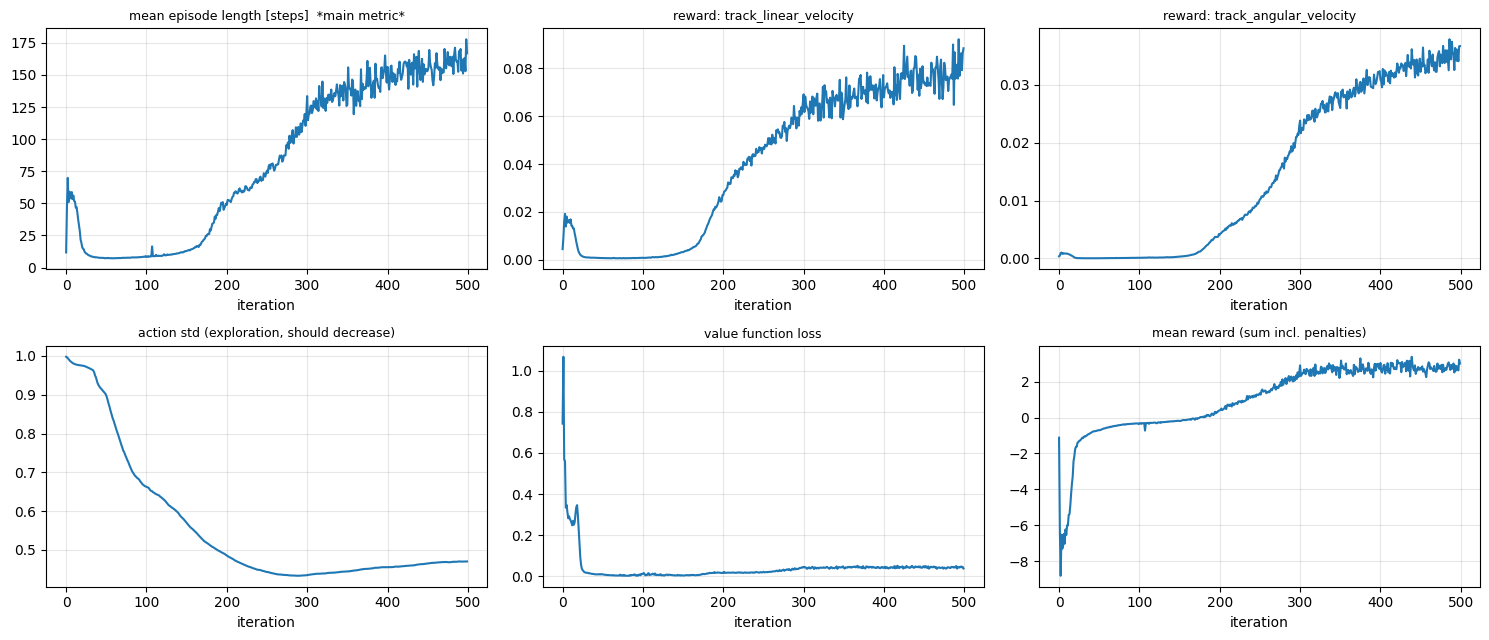

In [ ]:
import glob, os
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

RUN_DIR = sorted(glob.glob("logs/rsl_rl/g1_velocity/*_notebook"))[-1]   # 直近的 run
print("run:", RUN_DIR)

PANELS = [  # (TensorBoard 的标签, 显示标签)
    ("Train/mean_episode_length",            "mean episode length [steps]  *main metric*"),
    ("Episode_Reward/track_linear_velocity", "reward: track_linear_velocity"),
    ("Episode_Reward/track_angular_velocity","reward: track_angular_velocity"),
    ("Policy/mean_std",                      "action std (exploration, should decrease)"),
    ("Loss/value",                           "value function loss"),
    ("Train/mean_reward",                    "mean reward (sum incl. penalties)"),
]
files = sorted(glob.glob(os.path.join(RUN_DIR, "**", "events.out.tfevents.*"), recursive=True), key=os.path.getmtime)
ea = EventAccumulator(files[-1], size_guidance={"scalars": 0}); ea.Reload()
avail = set(ea.Tags().get("scalars", []))
panels = [(t, lab) for t, lab in PANELS if t in avail]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), squeeze=False)
for ax in axes.flat: ax.axis("off")
for ax, (t, lab) in zip(axes.flat, panels):
    ax.axis("on"); sc = ea.Scalars(t)
    ax.plot([s.step for s in sc], [s.value for s in sc])
    ax.set_title(lab, fontsize=9); ax.set_xlabel("iteration"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. 让它走起来——从 checkpoint 到视频

在工作站上，实务流程是运行 mjlab 自带的 `play Mjlab-Velocity-Flat-Unitree-G1 --checkpoint_file=...`，在 GUI viewer 中交互检查策略。在无头 notebook 中手动完成相同流程：取得 **play 环境配置**（无观测噪声、无推搡、仅 1 个实例、episode 实际上不限时），从 `logs/` 的最新 checkpoint 恢复策略，rollout 后写成 mp4。

关键在于它与训练进程相互独立。即使 Colab 断开，只要 `logs/` 还在（或能从 Drive 恢复），只运行这个 cell 就能重新生成视频。

> 渲染使用 `MUJOCO_GL=egl`（可在 Colab GPU runtime 中运行）。如果某个环境的 EGL 失败，请先执行 `!apt-get install -y libosmesa6`，再把 §0 中的 `os.environ["MUJOCO_GL"]` 改为 `"osmesa"` 并重跑。


In [ ]:
import glob, re
from dataclasses import asdict
from pathlib import Path

import mediapy as media
import numpy as np
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg

RUN_DIR = sorted(glob.glob("logs/rsl_rl/g1_velocity/*_notebook"))[-1]
ckpt = max(Path(RUN_DIR).glob("model_*.pt"),
           key=lambda p: int(re.search(r"model_(\d+)", p.name).group(1)))   # 最新checkpoint
print("checkpoint:", ckpt)

play_cfg = load_env_cfg(TASK, play=True)   # 重新生用的変種(噪声・突飛无是 env_cfgs.py 的 play 分岐参照)
play_cfg.scene.num_envs = 1                # 视频是1体仅
play_cfg.viewer.height, play_cfg.viewer.width = 480, 640
agent_cfg = load_rl_cfg(TASK)

raw_env = ManagerBasedRlEnv(cfg=play_cfg, device=DEVICE, render_mode="rgb_array")
env = RslRlVecEnvWrapper(raw_env, clip_actions=agent_cfg.clip_actions)
runner = MjlabOnPolicyRunner(env, asdict(agent_cfg), device=DEVICE)   # log_dir 无=推理用
runner.load(str(ckpt), load_cfg={"actor": True}, strict=True, map_location=DEVICE)
policy = runner.get_inference_policy(device=DEVICE)

obs = env.get_observations()
frames = []
for _ in range(300):                       # 50 step = 1 秒 → 6 秒部分
    with torch.no_grad():
        action = policy(obs)               # 观测 → 动作(每个关节的目标角)
    obs, _, _, _ = env.step(action)        # wrapper 経由是 (obs, reward, dones, extras) 的4要素
    frame = np.asarray(raw_env.render())
    frames.append(frame[0] if frame.ndim == 4 else frame)
env.close()

Path("videos").mkdir(exist_ok=True)
media.write_video("videos/g1_walk.mp4", frames, fps=int(raw_env.metadata.get("render_fps", 50)))
print(f"videos/g1_walk.mp4 保存到({len(frames)} frames)")

checkpoint: logs/rsl_rl/g1_velocity/2026-07-12_22-44-45_notebook/model_499.pt
Warp 1.12.1 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.1
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon be removed from the public API. It can still be accessed from `warp._src.context.runtime` but might be changed or removed without notice.
Module mujoco_warp._src.smooth f756680 load on device 'cuda:0' took 8953.63 ms  (compiled)
Module mujoco_warp._src.collision_driver 4d8b905 load on device 'cuda:0' took 147.47 ms  (compiled)
Module _nxn_broadphase__locals__kernel_e916423b e916423 load on device 'cuda:0' took 575.22 ms  (compiled)
Module _primitive_narrowphase__locals__primitive_narrowphase_f33437d9 f33437d load on device 'cuda:0' took 1138.41 ms  (compiled)
Module mujoco_warp._src.constraint 63c97cb load on device 'cuda:0' took 3893.76 

In [ ]:
from IPython.display import Video, display
display(Video("videos/g1_walk.mp4", embed=True, width=480))

> 这是 500 iteration 的短训练，所以画面更接近“站住并尝试朝指令方向走”，还不是平滑步态。把 `MAX_ITERATIONS` 增加到数千后，会更接近官方演示。


## 6. 总结——下一步

本 notebook 走完了一次真实开发循环：

**阅读 MDP（§1）→ 小规模运行确认（§2）→ 用 CLI 训练（§3）→ 用曲线诊断（§4）→ 运行并确认（§5）**

后续工作就是不断重复这个循环：

- **改变步态**：从 §1.4 的奖励表入手。可以修改 `load_env_cfg()` 返回的 `cfg.rewards[...].weight`，再按 §2 创建环境并训练；也可以从 GitHub clone mjlab（`pip install -e`），直接修改 `tasks/velocity/` 中的权重并重新运行。这就是腿式机器人 RL 的日常开发循环。
- **延长训练**：使用 `--agent.max-iterations=3000` 以上得到更平滑的步态。想在崎岖地形行走，可以尝试带地形课程的 `Mjlab-Velocity-Rough-Unitree-G1`。
- **部署到真实机器人**：训练时会自动写出部署用 ONNX（`<run名>.onnx`，位于 `logs/`）。真实部署可参考 Unitree 官方的 [unitree_rl_mjlab](https://github.com/unitreerobotics/unitree_rl_mjlab) 仓库中的 `deploy/`。
- **创建自己的任务**：把 `mjlab/tasks/velocity/` 的结构（term 函数 + Cfg + `register_mjlab_task`）复制到自己的包中再修改，这是实务中常见的做法。manager 方式源自 Isaac Lab，因此同样的模式也适用于 Isaac Lab。
